## Ćwiczenie 6: Filtry wyostrzające i detekcja krawędzi

### 1. Wprowadzenie 
Na poprzednich zajęciach omawialiśmy **filtry dolnoprzepustowe** (uśredniający, Gauss), których zadaniem była redukcja szumu kosztem rozmycia (*blurring*) granic między tkankami. W diagnostyce obrazowej (np. RTG, TK, USG) redukcja szumu jest kluczowa dla podniesienia wskaźnika SNR, ale niesie ze sobą ryzyko zatarcia subtelnych granic narządów czy wczesnych zmian patologicznych.

Zadaniem **filtrów górnoprzepustowych (wyostrzających)** oraz **operatorów detekcji krawędzi** jest nie usuwanie szumu, lecz **uwypuklanie lokalnych różnic intensywności**, co stanowi fundament automatycznej segmentacji struktur anatomicznych.

---

### 2. Matematyka masek o sumie wag równej zero
Klasyczny filtr wygładzający posiadał wagi wyłącznie dodatnie, których suma wynosiła $1$:
$$\sum_{i} \sum_{j} h(i,j) = 1$$

W **filtrach wyostrzających i różnicujących** zasada budowy maski ulega radykalnej zmianie:
1. W masce występują **wagi ujemne**.
2. Suma wszystkich wag w masce wynosi najczęściej **$0$**:
$$\sum_{i} \sum_{j} h(i,j) = 0$$

#### Co to oznacza w praktyce?
* **Obszary jednorodne (płaskie):** Jeśli maska o sumie wag $0$ znajdzie się nad obszarem o stałej jasności (np. wnętrze jednolitej tkanki lub czarne tło), wartości sąsiadujących pikseli są niemal identyczne. Mnożenie ich przez wagi (dodatnie i ujemne) i zsumowanie daje wynik **równy lub bliski zeru**. Obszar staje się czarny.
* **Miejsca skoku jasności (krawędzie):** Gdy maska natrafi na granicę ośrodków o różnej gęstości (np. przejście z tkanki miękkiej na kość), ujemne i dodatnie wagi nie znoszą się wzajemnie. Wynik splotu przyjmuje dużą wartość (dodatnią lub ujemną), co skutkuje jasnym lub ciemnym zarysem krawędzi na obrazie wynikowym.

### 3. Przegląd klasycznych operatorów

W analizie obrazów medycznych stosuje się dwa główne podejścia oparte na pochodnych cząstkowych:

1. **Operotory gradientowe pierwszego rzędu (Sobel, Prewitt):**
   Szukają maksimum zmiany jasności w kierunku pionowym i poziomym. Ponieważ w jednym kierunku liczą różnicę, a w drugim w pewnym stopniu uśredniają, są **bardziej odporne na szum** niż czyste różniczkowanie.
   * Maska Sobela pozioma ($H_X$): wykrywa krawędzie poziome.
   * Maska Sobela pionowa ($H_Y$): wykrywa krawędzie pionowe.


2. **Operator Laplace'a (Laplasjan - drugi rząd):**
   Bezkierunkowy operator oparty na drugiej pochodnej. Wykrywa krawędzie we wszystkich kierunkach jednocześnie. Jego wadą jest **ekstremalna wrażliwość na szum**, dlatego w przetwarzaniu obrazów medycznych "czysty" Laplasjan stosuje się rzadko – standardem jest uprzednie wygładzenie obrazu filtrem Gaussa (**LoG – Laplacian of Gaussian**).

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


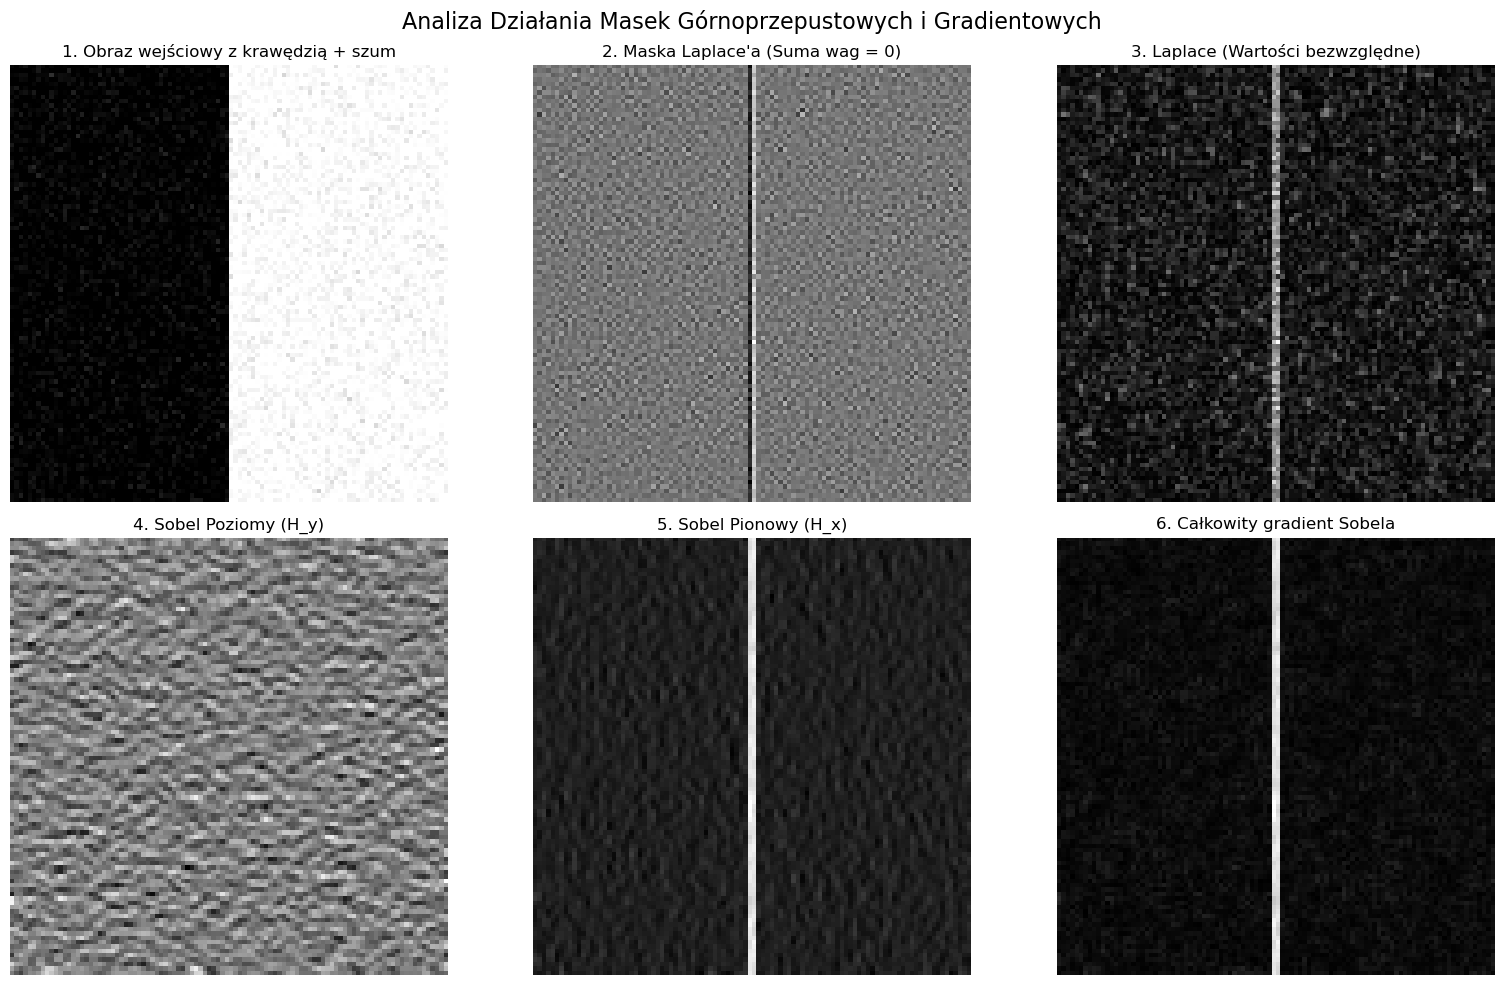

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from skimage import data, filters

# --- KROK 1: Symulacja sztucznego profilu krawędzi anatomicznej ---
# Tworzymy macierz z wyraźnym, ostrym skokiem jasności (symulacja granicy narządu)
synthetic_edge = np.zeros((100, 100), dtype=float)
synthetic_edge[:, 50:] = 1.0  # Lewa strona ciemna (0.0), prawa jasna (1.0)

# Dodajemy delikatny szum, by pokazać zachowanie operatorów
np.random.seed(42)
noisy_edge = synthetic_edge + np.random.normal(0, 0.05, synthetic_edge.shape)

# --- KROK 2: Definicja ręcznej maski Laplace'a (suma wag = 0) ---
kernel_laplace = np.array([
    [ 0, -1,  0],
    [-1,  4, -1],
    [ 0, -1,  0]
])

# Wykonanie splotu ręcznego
edge_laplace_result = convolve(noisy_edge, kernel_laplace)

# --- KROK 3: Użycie gotowych filtrów Sobela z scikit-image ---
edge_sobel_h = filters.sobel_h(noisy_edge)
edge_sobel_v = filters.sobel_v(noisy_edge)
edge_sobel_total = filters.sobel(noisy_edge)  # Moduł gradientu łącznego

# --- KROK 4: Wizualizacja wyników ---
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Analiza Działania Masek Górnoprzepustowych i Gradientowych', fontsize=16)

axes[0, 0].imshow(noisy_edge, cmap='gray', vmin=0, vmax=1)
axes[0, 0].set_title('1. Obraz wejściowy z krawędzią + szum')

axes[0, 1].imshow(edge_laplace_result, cmap='gray')
axes[0, 1].set_title('2. Maska Laplace\'a (Suma wag = 0)')

axes[0, 2].imshow(np.abs(edge_laplace_result), cmap='gray')
axes[0, 2].set_title('3. Laplace (Wartości bezwzględne)')

axes[1, 0].imshow(edge_sobel_h, cmap='gray')
axes[1, 0].set_title('4. Sobel Poziomy (H_y)')

axes[1, 1].imshow(edge_sobel_v, cmap='gray')
axes[1, 1].set_title('5. Sobel Pionowy (H_x)')

axes[1, 2].imshow(edge_sobel_total, cmap='gray')
axes[1, 2].set_title('6. Całkowity gradient Sobela')

for row in axes:
    for ax in row:
        ax.axis('off')

plt.tight_layout()
plt.show()

### 4. Podsumowanie i Wnioski Kliniczne

1. **Znoszenie się sygnałów:** w jednolitych obszarach po lewej i prawej stronie krawędzi, maska Laplace'a daje wartość bliską zera (szare/czarne tło). Sygnał pojawia się wyłącznie na samej granicy skoku jasności.
2. **Kierunkowość a wszechstronność:** maski Sobela pozwalają wyizolować krawędzie orientowane w konkretnej osi (pionowej lub poziomej), co bywa kluczowe przy analizie ułożenia naczyń krwionośnych lub struktur kostnych. Moduł gradientu (`filters.sobel`) łączy oba kierunki w jeden ostry zarys.
3. **Kwerstia szumu:** na zaszumionym obrazie testowym, czysty operator Laplace'a wykazuje dużą wrażliwość na pojedyncze fluktuacje (szum tła). Z tego powodu w kolejnych krokach laboratorium przejdziemy do hybrydowego podejścia **LoG (Laplacian of Gaussian)**.